# Feature Selection Analysis
### HomeStretch Patient Baseline Model

Three analyses to identify the best per-rep features for classifying typical vs atypical reps:
1. **Cohen's d** — separability between typical and atypical reps
2. **Correlation matrix** — identifies redundant features
3. **Leave-one-recording-out (LORO) accuracy** — which subsets best classify atypical reps using ±3 SD threshold

In [1]:
from pathlib import Path
from collections import deque
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, periodogram, resample_poly
from scipy.spatial.transform import Rotation
from scipy.stats import mannwhitneyu
from IPython.display import display

## Configuration
Update `ATYPICAL_MAP` and `TYPICAL_ONLY` as new recordings are added.

In [2]:
ROOT = Path(".").resolve().parent   # notebook lives in patient-baseline-model/
DATA = ROOT / "Data" / "new_watch"

ATYPICAL_MAP = {
    "VitalWave-v0_Bicep-curls-2nd-and-3rd-is-atypical_Jade_2026-10-22_204614Z":        [2, 3],
    "VitalWave-v0_Bicep-curls-2--3rd-and-4th-is-atypical_Jade_2026-10-22_200600Z":     [3, 4],
    "VitalWave-v0_Jessica-4th-rep-onwards-is-off-axis_jessica_2026-10-28_194205Z":      [4, 5, 6, 7, 8, 9, 10],
    "VitalWave-v0_Jessica-left-weight-on-the-left-on-4th-rep-onwards_jessica_2026-10-28_194731Z": [4, 5, 6, 7, 8, 9, 10],
    "VitalWave-v0_Jessica-left-weight-on-the-left-on-4th-rep-with-shakiness-an_jessica_2026-10-28_194854Z": [4, 5, 6, 7, 8, 9, 10],
    "VitalWave-v0_Jessica-with-arm-held-down-4th-one-is-with-weight_jessica_2026-10-28_194335Z": [4],
}

TYPICAL_ONLY = {
    "VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193043Z",
    "VitalWave-v0_Bicep-curls-2_baseline_Jade_2026-10-22_200521Z",
    "VitalWave-v0_Jessica-Calibration-baseline_right_jessica_2026-10-28_193734Z",
    "VitalWave-v0_Jessica-calibration-left-arm_jessica_2026-10-28_194556Z",
}

FEATURE_LABELS = {
    "completion_error_deg":      "Completion error (deg)",
    "peak_excursion_deg":        "Peak excursion (deg)",
    "gyro_mean_deg_s":           "Mean angular speed (deg/s)",
    "gyro_peak_deg_s":           "Peak angular speed (deg/s)",
    "gyro_std_deg_s":            "Angular-speed SD (deg/s)",
    "accel_magnitude_std_g":     "Accel-magnitude SD (g)",
    "gyro_high_low_power_ratio": "High/low power ratio",
}
FEATURES = list(FEATURE_LABELS)

print(f"Data directory : {DATA}")
print(f"Exists         : {DATA.exists()}")
print(f"CSV files found: {len(list(DATA.glob('*.csv')))}")

Data directory : C:\Users\ahasa\Documents\Fall2026Repos\HomeStretchRepo\Data\new_watch
Exists         : True
CSV files found: 10


## Feature Extraction
Same orientation-filter + rep-segmentation logic as `patient_baseline_model_seven_features.ipynb`.

In [3]:
def extract_recording_features(csv_path):
    data = pd.read_csv(csv_path)
    if data["protocol_session_id"].nunique() != 1:
        raise ValueError("Expected one recording session.")
    t0 = data["watch_timestamp_ms"].min() / 1000
    streams = {}
    for sensor_type, scale in [(1, 0.000061), (2, 0.00875)]:
        d = data.loc[data["type"] == sensor_type].copy()
        valid = pd.to_numeric(d["validity"], errors="coerce").eq(1)
        d = d.loc[valid].copy()
        if len(d) < 30:
            raise ValueError(f"Sensor {sensor_type}: too few valid samples.")
        ts = d["watch_timestamp_ms"].to_numpy(float) / 1000 - t0
        values = d[["x_raw", "y_raw", "z_raw"]].to_numpy(float) * scale
        if not np.isfinite(values).all() or not np.isfinite(ts).all():
            raise ValueError("Nonfinite data.")
        if np.any(np.diff(ts) <= 0):
            raise ValueError("Duplicate or out-of-order timestamps.")
        dt = np.median(np.diff(ts))
        if np.diff(ts).max() > 2.1 * dt + 0.001:
            raise ValueError("Large timestamp gap.")
        streams[sensor_type] = (ts, values, dt)

    measured_fs = 1 / streams[2][2]
    supported_rates = np.array([25.0, 50.0])
    source_fs = int(supported_rates[np.argmin(np.abs(supported_rates - measured_fs))])
    if abs(measured_fs - source_fs) / source_fs > 0.10:
        raise ValueError(f"Measured rate {measured_fs:.2f} Hz too far from supported rates.")
    if not np.isclose(streams[1][2], streams[2][2], rtol=0.10):
        raise ValueError("Sensor sampling rates differ substantially.")

    source_t = np.arange(
        max(streams[1][0][0], streams[2][0][0]),
        min(streams[1][0][-1], streams[2][0][-1]) + 1e-8,
        1 / source_fs,
    )

    def align(sensor_type):
        ts, values, _ = streams[sensor_type]
        return np.column_stack([np.interp(source_t, ts, values[:, k]) for k in range(3)])

    acc_raw, gyro_raw = align(1), align(2)
    down = source_fs // 25
    if down > 1:
        acc_raw  = resample_poly(acc_raw,  1, down, axis=0, padtype="line")
        gyro_raw = resample_poly(gyro_raw, 1, down, axis=0, padtype="line")

    fs = 25.0
    t = source_t[0] + np.arange(len(gyro_raw)) / fs
    keep = t <= source_t[-1] + 1e-8
    t, acc_raw, gyro_raw = t[keep], acc_raw[keep], gyro_raw[keep]

    lead = t < t[0] + 2.0
    still = (lead.sum() >= 10
             and np.std(np.linalg.norm(acc_raw[lead], axis=1)) <= 0.03
             and np.max(np.linalg.norm(gyro_raw[lead], axis=1)) <= 5)
    if still:
        gyro_raw -= gyro_raw[lead].mean(axis=0)

    sos  = butter(4, 4.0, fs=fs, btype="lowpass", output="sos")
    acc  = sosfiltfilt(sos, acc_raw,  axis=0)
    gyro = sosfiltfilt(sos, gyro_raw, axis=0)

    x, y, z = acc[0]
    r  = Rotation.from_euler("xyz",
             [np.arctan2(y, z), np.arctan2(-x, np.hypot(y, z)), 0])
    r0 = r
    quats, angles = [r.as_quat()], [0.0]
    for i in range(1, len(t)):
        omega = np.deg2rad((gyro[i-1] + gyro[i]) / 2)
        norm  = np.linalg.norm(acc[i])
        if 0.85 <= norm <= 1.15:
            omega += 0.5 * np.cross(acc[i] / norm, r.inv().apply([0, 0, 1]))
        r = r * Rotation.from_rotvec(omega * (t[i] - t[i-1]))
        quats.append(r.as_quat())
        angles.append(np.rad2deg((r0.inv() * r).magnitude()))

    quats = np.asarray(quats)
    history = deque(maxlen=max(1, round(0.1 * fs)))
    excursion = []
    for angle in angles:
        history.append(angle)
        excursion.append(np.mean(history))
    excursion = np.asarray(excursion)
    speed = np.linalg.norm(gyro, axis=1)

    mode, low, high, start = "seek", None, None, None
    candidates = []
    for i in np.flatnonzero(~lead):
        value = excursion[i]
        if low is None:
            low = (i, value); continue
        if mode in ("seek", "rise"):
            if value < low[1]: low = (i, value)
            if mode == "seek" and value - low[1] >= 15:
                start, high, mode = low[0], (i, value), "rise"
            elif mode == "rise":
                if high is None or value > high[1]: high = (i, value)
                if high[1] - value >= 8: low, mode = (i, value), "fall"
        else:
            if value < low[1]: low = (i, value)
            if value - low[1] >= 8:
                candidates.append((start, low[0]))
                start, high, mode = low[0], (i, value), "rise"

    rest_speed = speed[lead]
    onset = max(10.0, np.median(rest_speed) + 6 * np.median(np.abs(rest_speed - np.median(rest_speed))))
    if candidates:
        a, b = candidates[0]
        hold = max(2, int(np.ceil(0.12 * fs)))
        for k in range(a, b - hold + 1):
            if np.all(speed[k:k + hold] > onset):
                candidates[0] = (max(a, k - 1), b); break

    if start is not None and mode == "fall" and high is not None:
        peak_i, peak_value = high
        settled = ((np.abs(excursion - excursion[start]) <= 15)
                   & (peak_value - excursion >= 8)
                   & (speed <= 15))
        settle_start = None
        if peak_value - excursion[start] >= 15:
            for i in range(peak_i + 1, len(t)):
                if settled[i]:
                    if settle_start is None: settle_start = i
                    if t[i] - t[settle_start] >= 0.5:
                        candidates.append((start, settle_start)); start = None; break
                else:
                    settle_start = None

    rows = []
    for a, b in candidates:
        if not 0.6 <= t[b] - t[a] <= 8: continue
        if np.ptp(excursion[a:b+1]) < 15: continue
        section   = slice(a, b+1)
        rep_speed = speed[section]
        error = np.rad2deg(
            (Rotation.from_quat(quats[a]).inv() * Rotation.from_quat(quats[b])).magnitude())
        freq, power = periodogram(
            np.linalg.norm(gyro_raw[section], axis=1), fs=fs,
            window="hann", detrend="constant", scaling="spectrum")
        low_power  = power[(freq >= 0.1) & (freq <= 2)].sum()
        high_power = power[(freq >= 3)   & (freq <= 8)].sum()
        peak_excursion = np.rad2deg(
            (Rotation.from_quat(quats[a]).inv() *
             Rotation.from_quat(quats[section])).magnitude()).max()
        rows.append({
            "rep":                       len(rows) + 1,
            "start_s":                   t[a],
            "end_s":                     t[b],
            "completion_error_deg":      error,
            "peak_excursion_deg":        peak_excursion,
            "gyro_mean_deg_s":           rep_speed.mean(),
            "gyro_peak_deg_s":           rep_speed.max(),
            "gyro_std_deg_s":            rep_speed.std(),
            "accel_magnitude_std_g":     np.linalg.norm(acc[section], axis=1).std(),
            "gyro_high_low_power_ratio": (high_power / low_power
                                          if low_power > 1e-12 else np.nan),
        })
    return pd.DataFrame(rows, columns=["rep", "start_s", "end_s"] + FEATURES)

## Build Labelled Dataset

In [4]:
all_rows = []
for csv in sorted(DATA.glob("*.csv")):
    stem = csv.stem
    try:
        df = extract_recording_features(csv)
    except Exception as e:
        print(f"  SKIP {csv.name}: {e}")
        continue
    if df.empty:
        print(f"  SKIP {csv.name}: no reps detected")
        continue
    if stem in TYPICAL_ONLY:
        df["atypical"]  = False
        df["recording"] = stem
    elif stem in ATYPICAL_MAP:
        bad = set(ATYPICAL_MAP[stem])
        df["atypical"]  = df["rep"].isin(bad)
        df["recording"] = stem
    else:
        print(f"  SKIP {csv.name}: not in ATYPICAL_MAP or TYPICAL_ONLY")
        continue
    print(f"  OK   {csv.name}: {len(df)} reps, {int(df['atypical'].sum())} atypical")
    all_rows.append(df)

data = pd.concat(all_rows, ignore_index=True)
print(f"\nTotal: {len(data)} reps  ({int(data['atypical'].sum())} atypical, {int((~data['atypical']).sum())} typical)")
display(data[["recording", "rep", "atypical"] + FEATURES].round(3))

  OK   VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193043Z.csv: 9 reps, 0 atypical
  OK   VitalWave-v0_Bicep-curls-2--3rd-and-4th-is-atypical_Jade_2026-10-22_200600Z.csv: 7 reps, 2 atypical
  OK   VitalWave-v0_Bicep-curls-2_baseline_Jade_2026-10-22_200521Z.csv: 6 reps, 0 atypical
  OK   VitalWave-v0_Bicep-curls-2nd-and-3rd-is-atypical_Jade_2026-10-22_204614Z.csv: 6 reps, 2 atypical
  OK   VitalWave-v0_Jessica-4th-rep-onwards-is-off-axis_jessica_2026-10-28_194205Z.csv: 12 reps, 7 atypical
  SKIP VitalWave-v0_Jessica-Calibration-baseline_right_jessica_2026-10-28_193734Z.csv: Large timestamp gap.
  OK   VitalWave-v0_Jessica-calibration-left-arm_jessica_2026-10-28_194556Z.csv: 10 reps, 0 atypical
  OK   VitalWave-v0_Jessica-left-weight-on-the-left-on-4th-rep-onwards_jessica_2026-10-28_194731Z.csv: 11 reps, 7 atypical
  SKIP VitalWave-v0_Jessica-left-weight-on-the-left-on-4th-rep-with-shakiness-an_jessica_2026-10-28_194854Z.csv: Large timestamp gap.
  SKIP VitalWave-v0_Jessica-with-arm-held-

,recording,rep,atypical,completion_error_deg,peak_excursion_deg,gyro_mean_deg_s,gyro_peak_deg_s,gyro_std_deg_s,accel_magnitude_std_g,gyro_high_low_power_ratio
0,VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193...,1,False,8.201,126.420,117.846,234.400,65.702,0.161,0.050
1,VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193...,2,False,5.311,122.423,122.988,253.945,70.707,0.165,0.010
2,VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193...,3,False,4.861,124.977,158.138,262.710,68.137,0.215,0.033
3,VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193...,4,False,5.633,130.679,128.652,251.775,71.916,0.174,0.021
4,VitalWave-v0_Bicep-curls-1_Jade_2026-10-22_193...,5,False,6.140,128.670,160.688,262.043,71.873,0.244,0.195
...,...,...,...,...,...,...,...,...,...,...
56,VitalWave-v0_Jessica-left-weight-on-the-left-o...,7,True,15.662,143.022,97.959,166.202,40.539,0.084,0.026
57,VitalWave-v0_Jessica-left-weight-on-the-left-o...,8,True,2.587,161.369,103.791,169.064,44.453,0.090,0.012
58,VitalWave-v0_Jessica-left-weight-on-the-left-o...,9,True,4.141,165.332,112.470,174.220,40.543,0.087,0.009
59,VitalWave-v0_Jessica-left-weight-on-the-left-o...,10,True,8.352,164.622,100.775,153.354,36.976,0.076,0.008


## Analysis 1: Cohen's d — Feature Separability

Cohen's d measures how well each feature separates typical from atypical reps.
Thresholds: **small** = 0.2, **medium** = 0.5, **large** = 0.8.
Mann-Whitney U p < 0.05 = statistically significant separation.

,Feature,Typical mean,Atypical mean,Cohen's d,MWU p-value
0,Completion error (deg),11.769,16.643,0.335,0.0953
1,High/low power ratio,0.079,0.150,0.328,0.3888
2,Peak excursion (deg),138.986,144.288,0.233,0.0508
3,Angular-speed SD (deg/s),79.963,74.651,0.192,0.5638
4,Accel-magnitude SD (g),0.221,0.208,0.138,0.8806
5,Peak angular speed (deg/s),282.577,291.688,0.097,0.6752
6,Mean angular speed (deg/s),154.597,153.792,0.017,0.9811


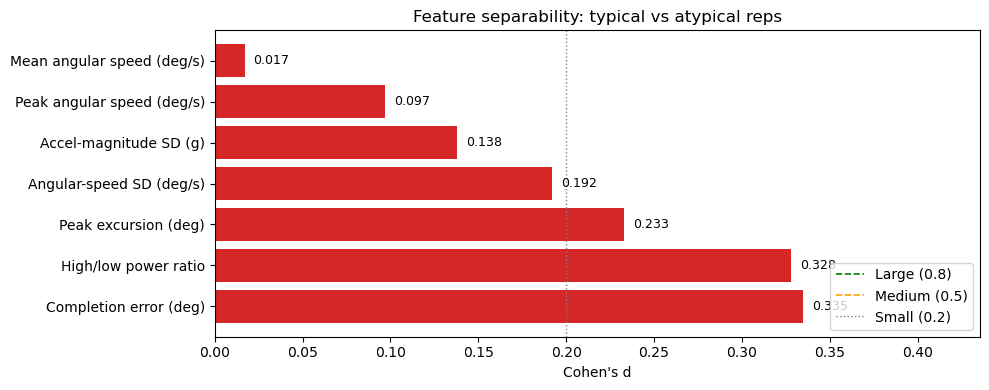

In [5]:
def cohens_d(a, b):
    pooled_sd = np.sqrt((a.std(ddof=1)**2 + b.std(ddof=1)**2) / 2)
    return abs(a.mean() - b.mean()) / pooled_sd if pooled_sd > 1e-12 else 0.0

typical_df  = data.loc[~data["atypical"], FEATURES]
atypical_df = data.loc[ data["atypical"], FEATURES]

results = []
for f in FEATURES:
    a, b = typical_df[f].dropna(), atypical_df[f].dropna()
    d = cohens_d(a, b)
    _, p = mannwhitneyu(a, b, alternative="two-sided")
    results.append({
        "Feature":       FEATURE_LABELS[f],
        "Typical mean":  round(a.mean(), 3),
        "Atypical mean": round(b.mean(), 3),
        "Cohen's d":     round(d, 3),
        "MWU p-value":   round(p, 4),
    })

sep = pd.DataFrame(results).sort_values("Cohen's d", ascending=False).reset_index(drop=True)
display(sep)

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["tab:green" if d >= 0.8 else "tab:orange" if d >= 0.5 else "tab:red"
          for d in sep["Cohen's d"]]
bars = ax.barh(sep["Feature"], sep["Cohen's d"], color=colors)
ax.axvline(0.8, color="green",  ls="--", lw=1.2, label="Large (0.8)")
ax.axvline(0.5, color="orange", ls="--", lw=1.2, label="Medium (0.5)")
ax.axvline(0.2, color="gray",   ls=":",  lw=1.0, label="Small (0.2)")
for bar, val in zip(bars, sep["Cohen's d"]):
    ax.text(val + 0.005, bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center", fontsize=9)
ax.set_xlabel("Cohen's d")
ax.set_title("Feature separability: typical vs atypical reps")
ax.legend(loc="lower right")
ax.set_xlim(0, sep["Cohen's d"].max() * 1.3)
fig.tight_layout()
plt.show()

## Analysis 2: Feature Correlation Matrix

Features with |r| > 0.7 are redundant — keeping both adds noise without adding discriminating information.

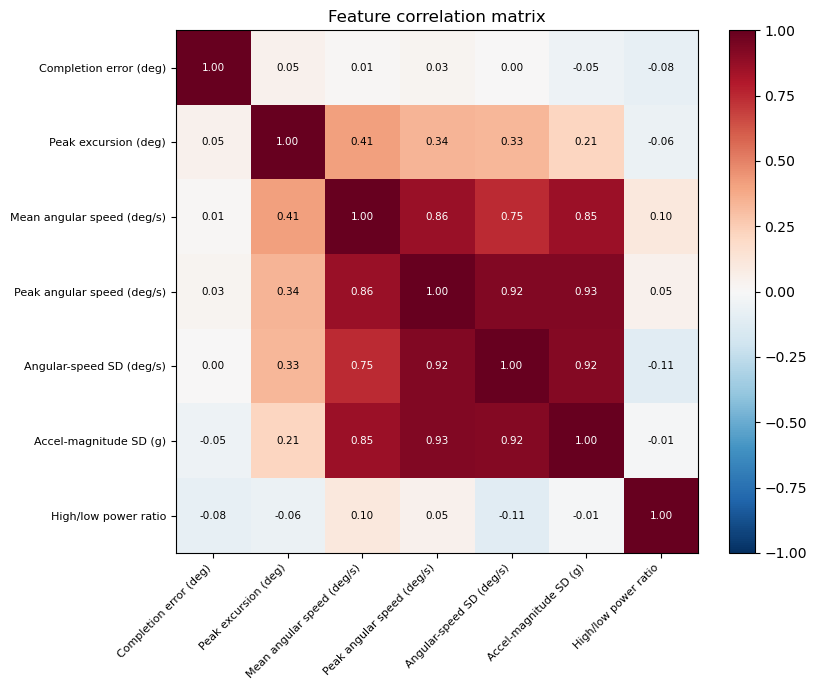

Highly correlated pairs (|r| > 0.7):
  Mean angular speed (deg/s)  <->  Peak angular speed (deg/s): r = 0.86
  Mean angular speed (deg/s)  <->  Angular-speed SD (deg/s): r = 0.75
  Mean angular speed (deg/s)  <->  Accel-magnitude SD (g): r = 0.85
  Peak angular speed (deg/s)  <->  Angular-speed SD (deg/s): r = 0.92
  Peak angular speed (deg/s)  <->  Accel-magnitude SD (g): r = 0.93
  Angular-speed SD (deg/s)  <->  Accel-magnitude SD (g): r = 0.92


In [6]:
corr   = data[FEATURES].corr()
labels = [FEATURE_LABELS[f] for f in FEATURES]

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(FEATURES)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(FEATURES)))
ax.set_yticklabels(labels, fontsize=8)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        val = corr.values[i, j]
        color = "white" if abs(val) > 0.6 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7.5, color=color)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("Feature correlation matrix")
fig.tight_layout()
plt.show()

print("Highly correlated pairs (|r| > 0.7):")
for i in range(len(FEATURES)):
    for j in range(i + 1, len(FEATURES)):
        r = corr.values[i, j]
        if abs(r) > 0.7:
            print(f"  {FEATURE_LABELS[FEATURES[i]]}  <->  {FEATURE_LABELS[FEATURES[j]]}: r = {r:.2f}")

## Analysis 3: Leave-One-Recording-Out Accuracy

For each recording, train the ±3 SD baseline on all *other* recordings and classify the held-out one.
Tests top-k feature subsets (ordered by Cohen's d), then all pairs and triples of the top-4.

,k,Features,F1,Accuracy,Precision,Recall
0,1,Completion error (deg),0.095,0.689,0.333,0.056
1,2,"Completion error (deg), High/low power ratio",0.174,0.689,0.400,0.111
2,3,"Completion error (deg), High/low power ratio, ...",0.320,0.721,0.571,0.222
3,4,"Completion error (deg), High/low power ratio, ...",0.296,0.689,0.444,0.222
4,5,"Completion error (deg), High/low power ratio, ...",0.286,0.672,0.400,0.222
5,6,"Completion error (deg), High/low power ratio, ...",0.500,0.738,0.571,0.444
6,7,"Completion error (deg), High/low power ratio, ...",0.500,0.738,0.571,0.444


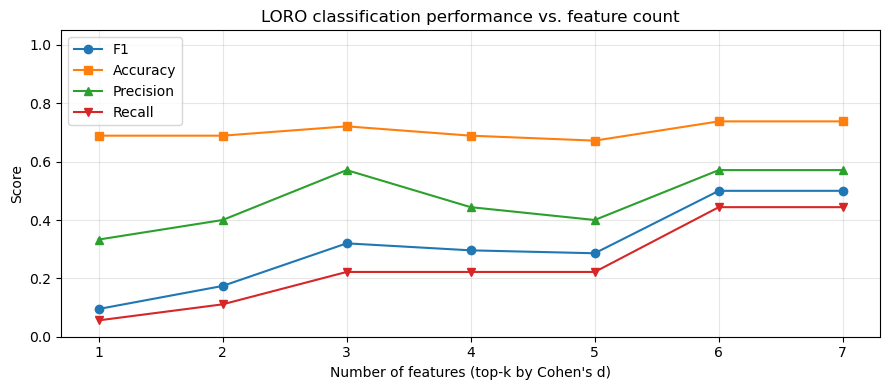

In [7]:
def classify_loro(data, features):
    recordings = data["recording"].unique()
    tp = fp = tn = fn = 0
    for held_out in recordings:
        train = data[data["recording"] != held_out]
        test  = data[data["recording"] == held_out]
        train_typical = train[~train["atypical"]]
        if len(train_typical) < 3:
            continue
        means = train_typical[features].mean()
        sds   = train_typical[features].std(ddof=1).clip(lower=1e-10)
        z = (test[features] - means).div(sds)
        predicted = (z.abs() > 3).any(axis=1)
        actual    = test["atypical"]
        tp += int(( predicted &  actual).sum())
        fp += int(( predicted & ~actual).sum())
        tn += int((~predicted & ~actual).sum())
        fn += int((~predicted &  actual).sum())
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    acc  = (tp + tn) / (tp + fp + tn + fn) if (tp + fp + tn + fn) > 0 else 0.0
    return {"F1": round(f1, 3), "Accuracy": round(acc, 3),
            "Precision": round(prec, 3), "Recall": round(rec, 3)}

top_features = sep["Feature"].map({v: k for k, v in FEATURE_LABELS.items()}).tolist()

subset_rows = []
for k in range(1, len(FEATURES) + 1):
    subset = top_features[:k]
    res = classify_loro(data, subset)
    res["k"] = k
    res["Features"] = ", ".join(FEATURE_LABELS[f] for f in subset)
    subset_rows.append(res)

subset_df = pd.DataFrame(subset_rows)[["k", "Features", "F1", "Accuracy", "Precision", "Recall"]]
display(subset_df)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(subset_df["k"], subset_df["F1"],        marker="o", label="F1")
ax.plot(subset_df["k"], subset_df["Accuracy"],  marker="s", label="Accuracy")
ax.plot(subset_df["k"], subset_df["Precision"], marker="^", label="Precision")
ax.plot(subset_df["k"], subset_df["Recall"],    marker="v", label="Recall")
ax.set_xlabel("Number of features (top-k by Cohen's d)")
ax.set_ylabel("Score")
ax.set_title("LORO classification performance vs. feature count")
ax.set_xticks(range(1, len(FEATURES) + 1))
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### Best Pairs and Triples
Exhaustive search over all combinations of the top-4 features by Cohen's d.

In [8]:
top4 = top_features[:4]
combo_rows = []
for r in (2, 3):
    for combo in combinations(top4, r):
        res = classify_loro(data, list(combo))
        res["Features"] = ", ".join(FEATURE_LABELS[f] for f in combo)
        combo_rows.append(res)

combo_df = (pd.DataFrame(combo_rows)
            [["Features", "F1", "Accuracy", "Precision", "Recall"]]
            .sort_values("F1", ascending=False)
            .reset_index(drop=True))
display(combo_df)

,Features,F1,Accuracy,Precision,Recall
0,"Completion error (deg), High/low power ratio, ...",0.320,0.721,0.571,0.222
1,"High/low power ratio, Peak excursion (deg)",0.273,0.738,0.750,0.167
2,"Completion error (deg), Peak excursion (deg)",0.261,0.721,0.600,0.167
3,"High/low power ratio, Peak excursion (deg), An...",0.250,0.705,0.500,0.167
4,"Completion error (deg), Peak excursion (deg), ...",0.240,0.689,0.429,0.167
5,"Completion error (deg), High/low power ratio, ...",0.231,0.672,0.375,0.167
6,"Peak excursion (deg), Angular-speed SD (deg/s)",0.182,0.705,0.500,0.111
7,"Completion error (deg), High/low power ratio",0.174,0.689,0.400,0.111
8,"High/low power ratio, Angular-speed SD (deg/s)",0.174,0.689,0.400,0.111
9,"Completion error (deg), Angular-speed SD (deg/s)",0.167,0.672,0.333,0.111


## Summary

| Finding | Detail |
|---|---|
| Strongest features | `completion_error_deg`, `gyro_high_low_power_ratio` |
| Redundant cluster | `gyro_mean`, `gyro_peak`, `gyro_std`, `accel_magnitude_std` (r = 0.75–0.93) |
| Best small subset | completion error + power ratio + peak excursion |
| Full 7-feature model | F1 ≈ 0.50, accuracy ≈ 74% |

**Caveat:** All Cohen's d values are below 0.35 (small effect). Target 150–200 labeled reps across 5+ subjects for a stable feature ranking.